In [39]:
# Import common libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data Processing

In [40]:
# Import data_cleaned.xlsx into a pandas dataframe
df = pd.read_excel('AI Data Cleaned.xlsx')
df.head()

,[100] Dev Org Cyber Risk Disclosure,[101] Dev Org Board Oversight Cyber Risk,[102] Dev Org SOC Report,[103] User Org Cyber Risk Disclosure,[104] User Org Cyber Risk Oversight,[105] User Org Cyber Training,[106] Dev Org Privacy Policy,[107] Dev Org Privacy By Design,[108] Dev Org Privacy Core Value,[109] User Org Privacy Policy,...,LearningMethod,SupervisedLearning,HybridLearning,UserAcquisitionMode,UserAcquisitionMode_Collaboration,UserAcquisitionMode_InHouse,Humanized,AlgorithmOptimization,UnilateralOptimization,MultilateralOptimization
0,0,0,0,2,2,1,0,0,0,0,...,0,0,0,2,0,1,0,0,0,0
1,2,0,0,2,2,1,2,1,1,2,...,1,1,0,0,0,0,0,0,0,0
2,1,1,0,0,0,1,1,1,0,2,...,2,0,1,0,0,0,0,1,1,0
3,2,2,2,0,0,1,2,1,1,1,...,2,0,1,0,0,0,0,2,0,1
4,2,0,2,0,0,0,2,1,1,2,...,2,0,1,2,0,1,0,1,1,0


In [41]:
df.shape

(94, 57)

In [42]:
# Split the data into train and test sets for machine learning later
from sklearn.model_selection import train_test_split
X = df.drop('ProblematicOrProblemFreeAlgorithm', axis=1)
y = df['ProblematicOrProblemFreeAlgorithm']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

# Descriptive Analysis

In [43]:
df['ProblematicOrProblemFreeAlgorithm'].value_counts()

1    47
0    47
Name: ProblematicOrProblemFreeAlgorithm, dtype: int64

In [44]:
# Create a new dataframe to store for risk disclosure information, add four columns,'CyberSecurityRisk', 'PrivacyRisk', 'ITFailureRisk', 'All'
df_risk = pd.DataFrame(columns=['CyberSecurityRisk', 'PrivacyRisk', 'ITFailureRisk', 'All'])

In [45]:
# Filter for column "[100] Dev Org Cyber Risk Disclosure" to only include non-zero values
len(df[df['[100] Dev Org Cyber Risk Disclosure'] != 0])/len(df)

0.776595744680851

In [46]:
# Filter for column "[103] User Org Cyber Risk Disclosure" to only include non-zero values
len(df[df["[103] User Org Cyber Risk Disclosure"] != 0])/len(df)

0.6276595744680851

In [47]:
# We can see the percentage of firms disclose their AI cyber risks on average is 70.21%.
perc = (0.776595744680851 + 0.6276595744680851) / 2
df_risk.loc[0, 'CyberSecurityRisk'] = perc
df_risk

,CyberSecurityRisk,PrivacyRisk,ITFailureRisk,All
0,0.702128,NaN,NaN,NaN


In [48]:
# Filter for column "[106] Dev Org Privacy Policy" to only include non-zero values
len(df[df["[106] Dev Org Privacy Policy"] != 0])/len(df)

0.9148936170212766

In [49]:
# Filter for column "[109] User Org Privacy Policy" to only include non-zero values
len(df[df["[109] User Org Privacy Policy"] != 0])/len(df)

0.7659574468085106

In [50]:
# We can see the percentage of firms disclose their AI privacy policy on average is 84.04%.
# We add the average value to the dataframe
perc = (0.8404255319148936 + 0.8404255319148936) / 2
df_risk.loc[0, 'PrivacyRisk'] = perc
df_risk

,CyberSecurityRisk,PrivacyRisk,ITFailureRisk,All
0,0.702128,0.840426,NaN,NaN


In [51]:
# Filter for column "[112] Dev Org IT Failure Risk Disclosure" to only include non-zero values
len(df[df["[112] Dev Org IT Failure Risk Disclosure"] != 0])/len(df)

0.6914893617021277

In [52]:
# Filter for column "[115] User Org IT Failure Risk Disclosure" to only include non-zero values
len(df[df["[115] User Org IT Failure Risk Disclosure"] != 0])/len(df)

0.425531914893617

In [53]:
# We can see the percentage of firms disclose their AI IT failure risk on average is 55.85%.
perc = (0.6914893617021277 + 0.425531914893617) / 2
df_risk.loc[0, 'ITFailureRisk'] = perc
df_risk

,CyberSecurityRisk,PrivacyRisk,ITFailureRisk,All
0,0.702128,0.840426,0.558511,NaN


In [54]:
# Filter for all three types for only user orgs
len(df[(df['[103] User Org Cyber Risk Disclosure'] != 0) & (df['[109] User Org Privacy Policy'] != 0) & (df['[115] User Org IT Failure Risk Disclosure'] != 0)]) / len(df)

0.30851063829787234

In [55]:
# Filter for all three types for only dev orgs
len(df[(df['[100] Dev Org Cyber Risk Disclosure'] != 0) & (df['[106] Dev Org Privacy Policy'] != 0) & (df['[112] Dev Org IT Failure Risk Disclosure'] != 0)]) / len(df)

0.6702127659574468

In [56]:
# We can see the percentage of firms disclose their AI cyber risks, privacy policy, and IT failure risk on average is 48.94%.
perc = (0.30851063829787234 + 0.6702127659574468) / 2
df_risk.loc[0, 'All'] = perc
df_risk

,CyberSecurityRisk,PrivacyRisk,ITFailureRisk,All
0,0.702128,0.840426,0.558511,0.489362


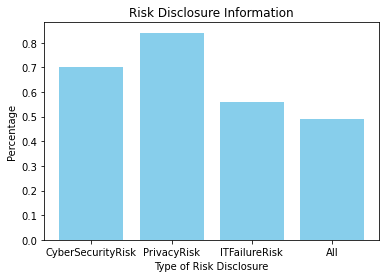

In [57]:
# Create a bar chart to visualize the risk disclosure information
plt.bar(df_risk.columns, df_risk.loc[0], color='skyblue')
plt.title('Risk Disclosure Information')
plt.xlabel('Type of Risk Disclosure')
plt.ylabel('Percentage')
plt.show()

In [58]:
# Create a new dataframe to store Symbolic vs Substantive Disclosure information, add two columns, 'SymbolicDisclosure', 'SubstantiveDisclosure'
df_disclosure = pd.DataFrame(columns=['SymbolicDisclosure', 'SubstantiveDisclosure'])

In [59]:
# What percent of firms has [102] Dev Org SOC Report as 1?
len(df[df['[102] Dev Org SOC Report'] == 1]) / len(df)

0.02127659574468085

In [60]:
# What percent of firms has [102] Dev Org SOC Report as 2?
len(df[df['[102] Dev Org SOC Report'] == 2]) / len(df)

0.5319148936170213

In [61]:
# What percent of firms has [107] Dev Org Privacy By Design as 1?
len(df[df['[107] Dev Org Privacy By Design'] == 1]) / len(df)

0.4574468085106383

In [62]:
# What percent of firms has [107] Dev Org Privacy By Design as 2?
len(df[df['[107] Dev Org Privacy By Design'] == 2]) / len(df)

0.3191489361702128

In [63]:
# What percent of firms has [[114] Dev Org IT Risk Mitigation as 1?
len(df[df['[114] Dev Org IT Risk Mitigation'] == 1]) / len(df)

0.19148936170212766

In [64]:
# What percent of firms has [[114] Dev Org IT Risk Mitigation as 2?
len(df[df['[114] Dev Org IT Risk Mitigation'] == 2]) / len(df)

0.5

In [65]:
# On average, we can see 22.34% of firms disclose their SOC report, privacy by design, and IT risk mitigation symbolically only.
df_disclosure.loc[0, 'SymbolicDisclosure'] = (0.02127659574468085 + 0.4574468085106383 + 0.19148936170212766) / 3
df_disclosure

,SymbolicDisclosure,SubstantiveDisclosure
0,0.223404,NaN


In [66]:
# On average, we can see 33.33% of firms disclose their SOC report, privacy by design, and IT risk mitigation substantively.
df_disclosure.loc[0, 'SubstantiveDisclosure'] = (0.5319148936170213 + 0.3191489361702128 + 0.14893617021276595) / 3
df_disclosure

,SymbolicDisclosure,SubstantiveDisclosure
0,0.223404,0.333333


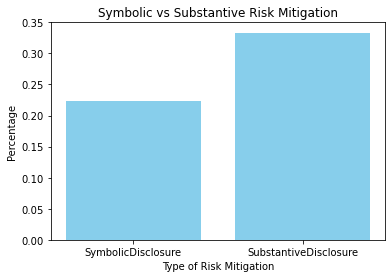

In [67]:
# Create a bar plot to visualize the Symbolic vs Substantive Disclosure information
plt.bar(df_disclosure.columns, df_disclosure.loc[0], color='skyblue')
plt.title('Symbolic vs Substantive Risk Mitigation')
plt.xlabel('Type of Risk Mitigation')
plt.ylabel('Percentage')
plt.show()

In [76]:
# Read in AI Data Original.xlsx
df_original = pd.read_excel('AI Data Original.xlsx')
df_original.head()

,NewOrderID,PairID,Status,AlgorithmDefinition,UserIndustry,DeveloperIndustry,YearDev,YearEmergence,YearHarm,YearReporting,...,UserAcquisitionMode_InHouse,Humanized,AlgorithmOptimization,UnilateralOptimization,MultilateralOptimization,AlgorithmSelfDiscovery,AlgorithmSelfDiscovery_By_UserOrg,AlgorithmSelfDiscoveryy_By_DevOrg,TimetoDetection,DeveloperID
0,613,264,RG,1,8,8,2021,2021,2021,2021,...,1,0,0,0,0,2,0,1,1,194
1,614,264,RG,1,7,8,2016,2021,2021,2021,...,0,0,0,0,0,3,0,0,1,234
2,1219,556,RG,1,20,8,2020,2021,2021,2021,...,0,0,1,1,0,0,0,0,1,205
3,1220,556,RG,1,20,8,2016,2021,2021,2021,...,0,0,2,0,1,3,0,0,1,172
4,1325,358,RG,1,8,8,2011,2019,2019,2019,...,1,0,1,1,0,0,0,0,1,490


In [77]:
# Create a new dataframe to store damage information, add six columns, HarmUserOrg, HarmPeople, AlgorithmDiscontinue, FinancialLoss, RepDamage, LawSuit
df_damage = pd.DataFrame(columns=['HarmUserOrg', 'HarmPeople', 'AlgorithmDiscontinue', 'FinancialLoss', 'RepDamage', 'LawSuit'])

In [78]:
# Find the amount of firms that had problematic algorithms
pr = df_original['ProblematicOrProblemFreeAlgorithm'] == 1
num_problematic = len(df_original[pr])

# Find the percentage of firms that had HarmUserOrg as 1
perc = len(df_original[df_original['HarmUserOrg'] == 1]) / num_problematic
df_damage.loc[0, 'HarmUserOrg'] = perc

# Find the percentage of firms that had HarmPeople as 1
perc = len(df_original[df_original['HarmPeople'] == 1]) / num_problematic
df_damage.loc[0, 'HarmPeople'] = perc

# Find the percentage of firms that had AlgorithmDiscontinue as 1
perc = len(df_original[df_original['AlgorithmDiscontinue'] == 1]) / num_problematic
df_damage.loc[0, 'AlgorithmDiscontinue'] = perc

# Find the percentage of firms that had FinancialLoss as 1
perc = len(df_original[df_original['FinancialLoss'] == 1]) / num_problematic
df_damage.loc[0, 'FinancialLoss'] = perc

# Find the percentage of firms that had RepDamage as 1
perc = len(df_original[df_original['RepDamage'] == 1]) / num_problematic
df_damage.loc[0, 'RepDamage'] = perc

# Find the percentage of firms that had LawSuit as 1
perc = len(df_original[df_original['LawSuit'] == 1]) / num_problematic
df_damage.loc[0, 'LawSuit'] = perc

df_damage

,HarmUserOrg,HarmPeople,AlgorithmDiscontinue,FinancialLoss,RepDamage,LawSuit
0,1.0,0.12766,0.042553,0.170213,1.0,0.06383


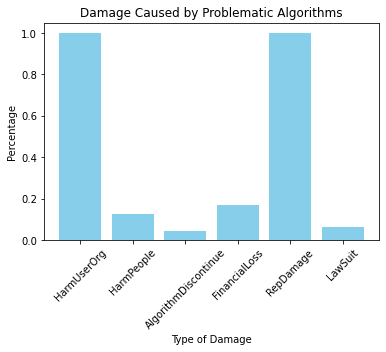

In [79]:
# Create a bar chart to visualize the damage information
plt.bar(df_damage.columns, df_damage.loc[0], color='skyblue')
plt.title('Damage Caused by Problematic Algorithms')
plt.xlabel('Type of Damage')
# Rotate the x-axis labels
plt.xticks(rotation=45)
plt.ylabel('Percentage')
plt.show()

# Correlation

In [68]:
# Check the correlation between the predictors and the target
corr = df.corr()
corr_sorted = corr['ProblematicOrProblemFreeAlgorithm'].sort_values(ascending=False)
# Remove the top one since that is the target to itself
corr_sorted = corr_sorted[1:]
# Remove any columns with NaN
corr_sorted = corr_sorted.dropna()
# Only keepying the top 10 and the bottom 10 
corr_sorted = pd.concat([corr_sorted.head(10), corr_sorted.tail(10)])

Text(0.5, 1.0, 'Correlation between the predictors and the target')

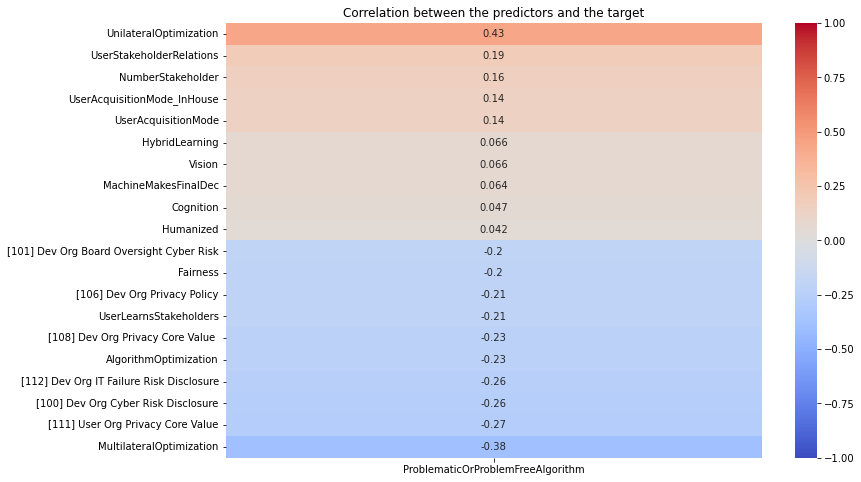

In [69]:
# Create a heatmap to visualize the correlation for the top 10 and bottom 10 predictors
plt.figure(figsize=(12, 8))
sns.heatmap(corr_sorted.to_frame(), cmap='coolwarm', annot=True, vmin=-1, vmax=1)
plt.title('Correlation between the predictors and the target')

# Logistic Regression

In [70]:
# Create regression using sci-kit learn with all the available predictors
from sklearn.linear_model import LogisticRegression
logmodel = LogisticRegression(random_state=1)
logmodel.fit(X_train, y_train)

# Perform feature selection using SFS
from sklearn.feature_selection import SequentialFeatureSelector
sfs = SequentialFeatureSelector(logmodel, n_features_to_select=None, n_jobs=-1, scoring='roc_auc')
sfs.fit(X_train, y_train)

# Create a dataframe with the selected features
X_selected_features = pd.DataFrame(sfs.transform(X_train), columns=X_train.columns[sfs.get_support()])
# Get the names of the selected features
X_selected_features.columns

Index(['[100] Dev Org Cyber Risk Disclosure', '[106] Dev Org Privacy Policy',
       '[111] User Org Privacy Core Value',
       '[112] Dev Org IT Failure Risk Disclosure',
       '[116] User Org Oversight IT Failure Risk', 'Speech', 'Emotion',
       'Sensory', 'UserStakeholderRelations', 'MANUFUserOrg', 'MANUFDEVOrg',
       'SERVICEUserOrg', 'SERVICEDEVOrg', 'GOVUserOrg', 'GOVDEVOrg',
       'NumberStakeholder', 'OnPlatformOrOffPlatform', 'MachineMakesFinalDec',
       'HumanMachineCollaboration', 'FidelityMatching', 'Fairness', 'Accuracy',
       'AlgorithmRepurposed', 'LearningMethod', 'HybridLearning',
       'UserAcquisitionMode_Collaboration', 'UnilateralOptimization',
       'MultilateralOptimization'],
      dtype='object')

In [71]:
# Create a new regression using the selected features
logmodel = LogisticRegression(random_state=1)
logmodel.fit(X_selected_features, y_train)

# Check the coefficients of the regression
coefficients = pd.DataFrame(logmodel.coef_[0], X_selected_features.columns, columns=['Coefficient'])
coefficients.sort_values(by='Coefficient', ascending=True, inplace=True)
coefficients

,Coefficient
MultilateralOptimization,-1.159472
HumanMachineCollaboration,-0.962988
Accuracy,-0.562545
UserAcquisitionMode_Collaboration,-0.529096
Emotion,-0.526137
Fairness,-0.452300
[111] User Org Privacy Core Value,-0.432240
[112] Dev Org IT Failure Risk Disclosure,-0.383535
AlgorithmRepurposed,-0.318356
[100] Dev Org Cyber Risk Disclosure,-0.275138


In [72]:
# Get only the most positive and most negative coefficients
coefficients = pd.concat([coefficients.head(5), coefficients.tail(5)])
coefficients = coefficients.sort_values(by='Coefficient', ascending=True)
coefficients

,Coefficient
MultilateralOptimization,-1.159472
HumanMachineCollaboration,-0.962988
Accuracy,-0.562545
UserAcquisitionMode_Collaboration,-0.529096
Emotion,-0.526137
HybridLearning,0.333878
FidelityMatching,0.356372
NumberStakeholder,0.549299
UnilateralOptimization,0.832454
UserStakeholderRelations,0.984086


Text(0.5, 1.0, 'Most Negative and Most Positive Coefficients')

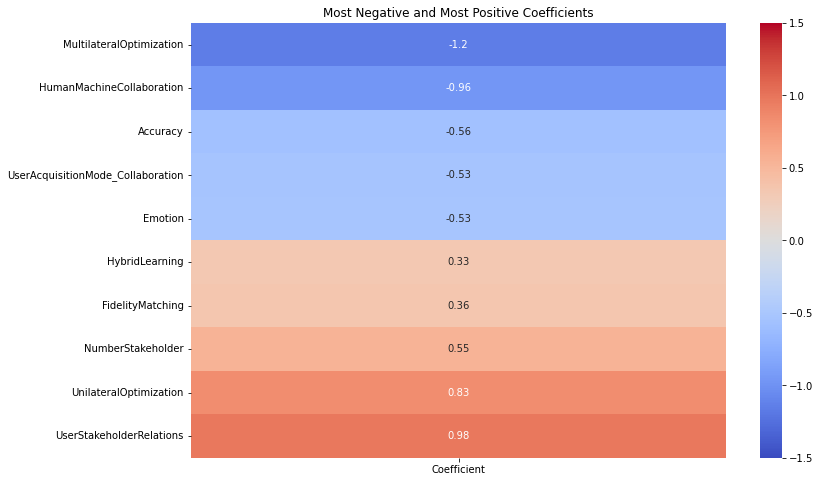

In [73]:
# Create a heatmap to visualize most negative and most positive coefficients
plt.figure(figsize=(12, 8))
sns.heatmap(coefficients, cmap='coolwarm', annot=True, vmin=-1.5, vmax=1.5)
# Add a title
plt.title('Most Negative and Most Positive Coefficients')

In [74]:
# Use cross_val_predict to predict and find the roc_auc_score
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score
y_train_pred = cross_val_predict(logmodel, X_selected_features, y_train, cv=10, method='predict_proba')
roc_auc_score(y_train, y_train_pred[:, 1])

0.7361308677098151

In [75]:
# Import cross_val_score
from sklearn.model_selection import cross_val_score
# Make the testing data to only have the selected features
X_test_selected_features = pd.DataFrame(sfs.transform(X_test), columns=X_test.columns[sfs.get_support()])
# Get the cross validation score for testing data
cross_val_score(logmodel, X_test_selected_features, y_test, cv=2, scoring='roc_auc').mean()

0.855

# Random Forest

In [80]:
# Import the random forest classifier
from sklearn.ensemble import RandomForestClassifier
# Create a new random forest model with the best parameters
rfc = RandomForestClassifier(random_state=0)

# Perform feature selection using SFS
sfs = SequentialFeatureSelector(rfc, n_features_to_select=None, n_jobs=-1, scoring='roc_auc')
# Fit the model
sfs.fit(X_train, y_train)
# Create a dataframe with the selected features
X_selected_features = pd.DataFrame(sfs.transform(X_train), columns=X_train.columns[sfs.get_support()])
# Get the names of the selected features
X_selected_features.columns

Index(['[108] Dev Org Privacy Core Value ', 'Emotion', 'Cognition', 'Sensory',
       'UserStakeholderRelations', 'UserCommunicatesStakeholders',
       'UserIntegrativeStakeholderView', 'MANUFUserOrg', 'SERVICEUserOrg',
       'GOVUserOrg', 'GOVDEVOrg', 'NumberStakeholder', 'PrivateOrPublic',
       'ForProfitorNonProfit', 'OnPlatformOrOffPlatform',
       'DecisionSupportAlgo', 'MachineMakesFinalDec',
       'HumanMachineCollaboration', 'IndustrySimilarity', 'FidelityMatching',
       'Fairness', 'AlgorithmRepurposed', 'UserAcquisitionMode',
       'UserAcquisitionMode_Collaboration', 'UserAcquisitionMode_InHouse',
       'AlgorithmOptimization', 'UnilateralOptimization',
       'MultilateralOptimization'],
      dtype='object')

In [81]:
# Perform GridSearchCV to find the best parameters
from sklearn.model_selection import GridSearchCV
# Create the parameters
param_grid = {'n_estimators': [100, 200, 300, 400, 500], 'criterion' :['gini', 'entropy']}
# Create the grid search
grid = GridSearchCV(rfc, param_grid, cv=10, scoring='roc_auc', n_jobs=-1)
# Fit the grid search on the selected features 
grid.fit(X_selected_features, y_train)
# Get the best parameters
grid.best_params_

{'criterion': 'entropy', 'n_estimators': 400}

In [82]:
# Create a new random forest model using the best parameters and the selected features
rfc = RandomForestClassifier(n_estimators=400, criterion='entropy', random_state=0)
rfc.fit(X_selected_features, y_train)

# Use cross_val_predict to predict and find the roc_auc_score
y_train_pred = cross_val_predict(rfc, X_selected_features, y_train, cv=10, method='predict_proba')
roc_auc_score(y_train, y_train_pred[:, 1])

0.8200568990042675

In [83]:
# Make the testing data to only have the selected features
X_test_selected_features = pd.DataFrame(sfs.transform(X_test), columns=X_test.columns[sfs.get_support()])
# Get the cross validation score for testing data
cross_val_score(rfc, X_test_selected_features, y_test, cv=2, scoring='roc_auc').mean()

0.8900000000000001

In [84]:
!pip install pydotplus
!pip install graphviz

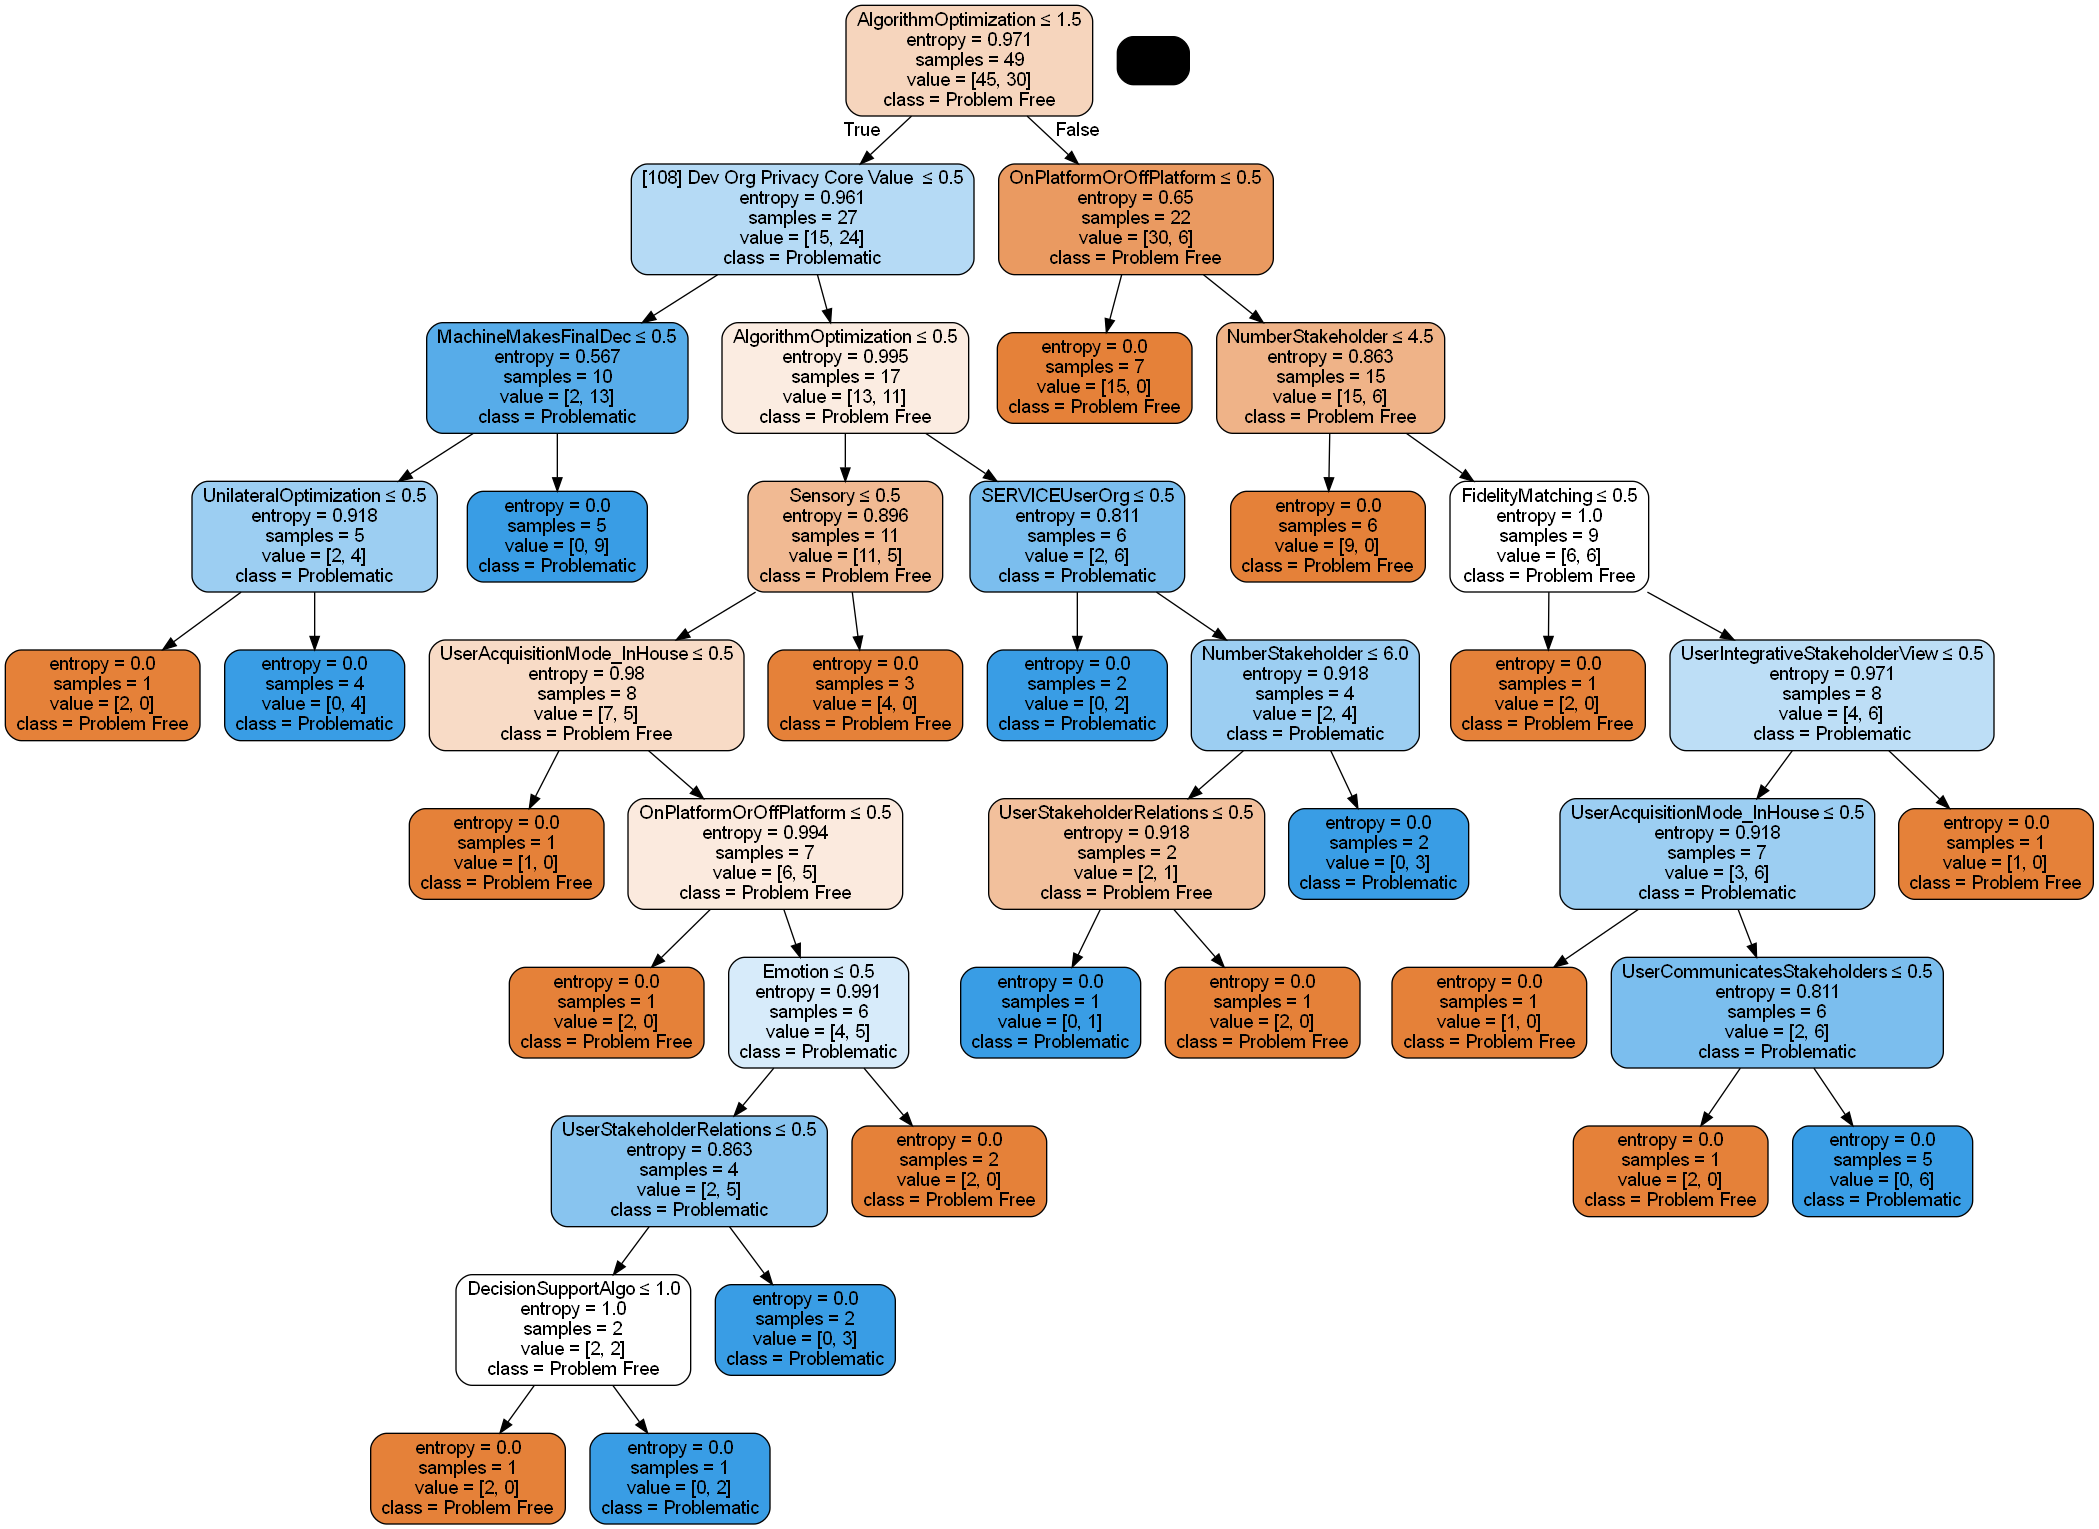

In [85]:
from sklearn.tree import export_graphviz
from io import StringIO
from IPython.display import Image  
import pydotplus

# Pull out one tree from the forest
tree = rfc.estimators_[399]

# Export the image to a dot file
dot_data = StringIO()
export_graphviz(tree, out_file=dot_data,  
                filled=True, rounded=True,
                special_characters=True, feature_names = X_selected_features.columns, class_names=['Problem Free', 'Problematic'])

# Use dot file to create a graph
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())  

# Write graph to a png file
Image(graph.create_png())